In [1]:
from scr import mutation_estimation

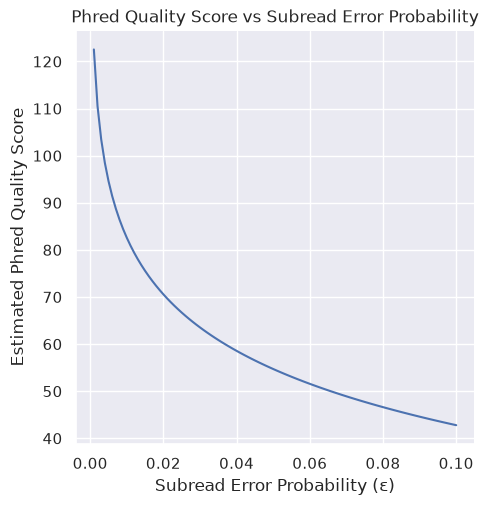

In [2]:
mutation_estimation.plot_phred_eps_dependency(0.001, 0.1, 100, 6)

### Cosmic Mutations

In [2]:
import pandas as pd

In [3]:
mutations = pd.read_csv("data/thyroid/nanoseq_mutation_data.tsv", sep="\t")
genome_tri_prop_path = "data/h19_tri32.csv"
seq_path = "data/thyroid/tnfrsf14.fasta"

Length of target sequence: 9744


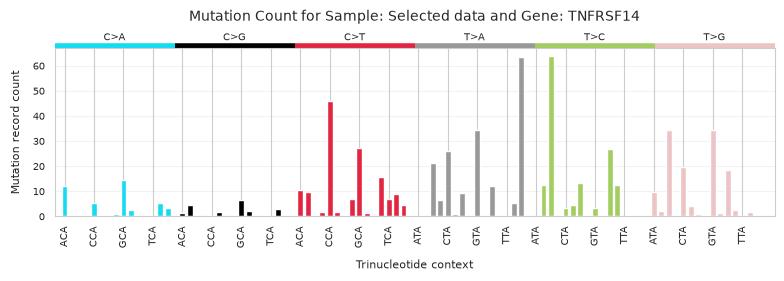

In [4]:
from scr.sbs96_computation import (
    add_sample_metadata,
    build_sbs96_matrix,
    select_mutations,
    tri_correct,
    plot_sbs96_matrix
)

mutations = add_sample_metadata(mutations)

selected = select_mutations(
    mutations,
    # donor_biopsy_id="PD63118b",
    gene="TNFRSF14",
)

matrix = build_sbs96_matrix(selected)
corr_matrix = tri_correct(mut_matrix=matrix, 
                          genome_tri_prop_path=genome_tri_prop_path,
                          seq_path=seq_path)

sbs96_matrix_ax = plot_sbs96_matrix(corr_matrix, save_image=False)

### Test of EM algorithm

In [5]:
from scr.signature_estimation import em_algorithm, em_visualization, signatures_visualization

In [6]:
cosmic_path = "data/COSMIC_v3.5_SBS_GRCh37.txt"

In [7]:
new_signature_prop, q_function_values, expected_counts_per_signature, normalized_mutation_df = em_algorithm(corr_matrix, cosmic_path, signature_prop=None, max_iter=100, tol=1e-5)

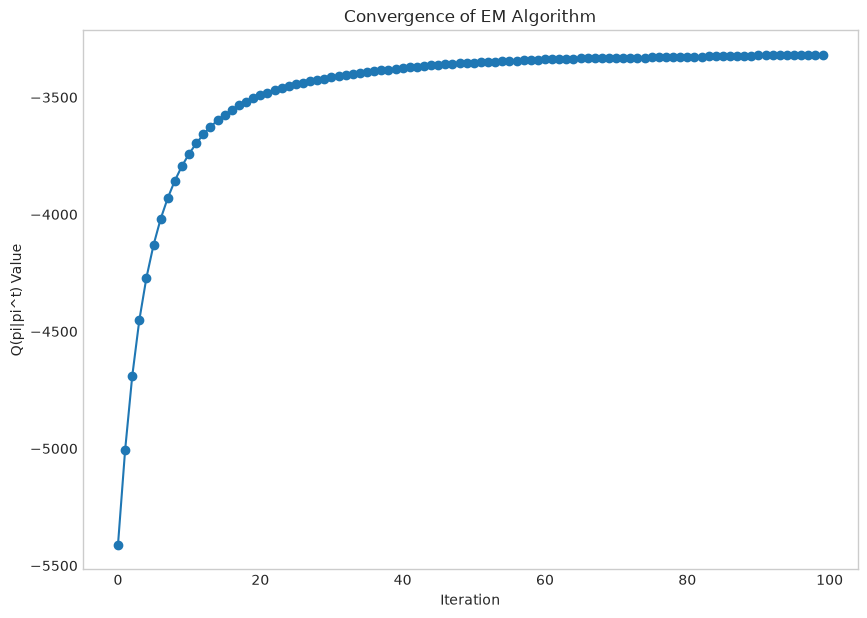

In [11]:
em_visualization(q_function_values)

### Singature composition visualization

In [8]:
totals = expected_counts_per_signature.sum(axis=0)
top_sbs = totals.nlargest(5).index

expected_counts_top_sbs = expected_counts_per_signature.loc[:, top_sbs]

/home/bee/code/mutrate/scr/signature_estimation.py:186: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


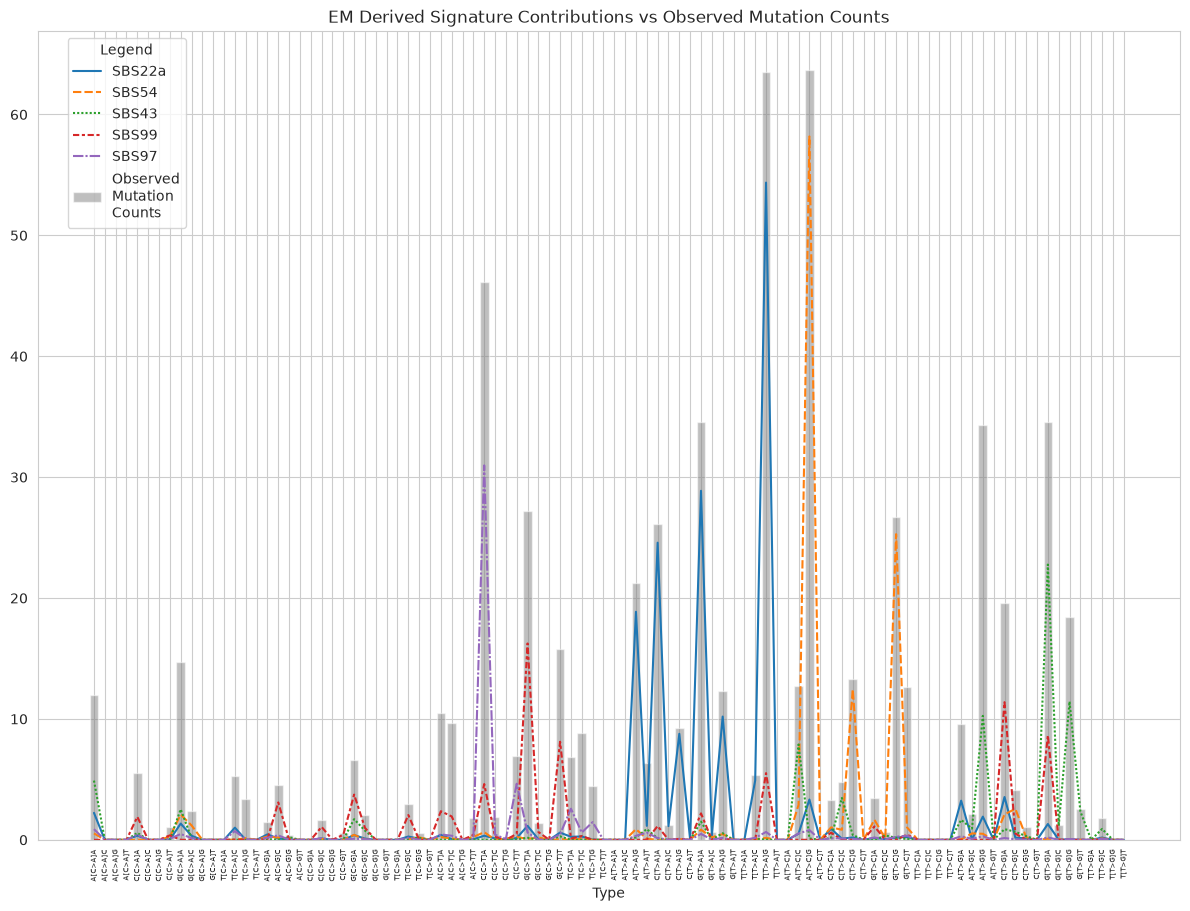

In [9]:
signatures_visualization(expected_counts_per_signature=expected_counts_top_sbs, normalized_matrix=normalized_mutation_df)

### Do it prettier

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
import re
import pandas as pd
import numpy as np

In [11]:
from matplotlib.patches import Patch

sns.set_style("whitegrid")

_SUBSTITUTIONS = ("C>A", "C>G", "C>T", "T>A", "T>C", "T>G")
_BASES = ("A", "C", "G", "T")
_CHANNELS = tuple(
    (substitution, f"{left}{substitution[0]}{right}")
    for substitution in _SUBSTITUTIONS
    for left in _BASES
    for right in _BASES
)

In [12]:
def plot_sbs96_matrix(
    matrix: pd.DataFrame,
    *,
    sample_label: str | None = None,
    gene: str | None = None,
    ax: plt.Axes | None = None, # type: ignore
    save_image: bool = False
) -> plt.Axes: # type: ignore
    """Plot SBS-96 counts with substitution colors, legend, and context ticks."""
    colors_list = ["#13DBF0", "#000000", "#E22642", "#999999", "#A2CD61", "#ECC4C5"]

    required = {"sub", "tri", "count"}
    missing = required.difference(matrix.columns)
    if missing:
        raise ValueError(f"matrix is missing required columns: {sorted(missing)}")

    indexed = matrix.set_index(["sub", "tri"])
    channels = pd.MultiIndex.from_tuples(_CHANNELS, names=["sub", "tri"])
    if len(indexed) != len(channels) or not indexed.index.is_unique:
        raise ValueError("matrix must contain exactly one row for each SBS-96 channel")
    ordered = indexed.reindex(channels)
    if ordered["count"].isna().any():
        raise ValueError("matrix does not contain all SBS-96 channels")

    if ax is None:
        _, ax = plt.subplots(figsize=(8, 3))

    colors = dict(zip(_SUBSTITUTIONS, colors_list))
    ax.bar(
        range(len(_CHANNELS)),
        pd.to_numeric(ordered["count"]).to_numpy(),
        color=[colors[sub] for sub, _ in _CHANNELS], # type: ignore
    )

    tick_positions = range(0, len(_CHANNELS), 4)
    ax.set_xticks(
        tick_positions,
        [_CHANNELS[i][1] for i in tick_positions],
    )
    ax.tick_params(axis="x", labelrotation=90, labelsize=7)
    ax.tick_params(axis="y", labelsize=7)
    ax.set_xlabel("Trinucleotide context", fontsize=8, labelpad=8)
    ax.set_ylabel("Mutation record count", fontsize=8, labelpad=8)
    sample_label = sample_label or matrix.attrs.get("sample_label", "Selected data")
    gene = gene or matrix.attrs.get("gene", "Unspecified")
    ax.set_title(f"Mutation Count for Sample: {sample_label} and Gene: {gene}", 
                 fontsize=10, pad=20)
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.25)

    for i, substitution in enumerate(_SUBSTITUTIONS):
        x0 = i / len(_SUBSTITUTIONS)
        x1 = (i + 1) / len(_SUBSTITUTIONS)
        color = colors[substitution]

        ax.plot(
            [x0, x1],
            [1.015, 1.015],
            transform=ax.transAxes,
            color=color,
            linewidth=4,
            solid_capstyle="butt",
            clip_on=False,
        )
        ax.text(
            (x0 + x1) / 2,
            1.035,
            substitution,
            transform=ax.transAxes,
            ha="center",
            va="bottom",
            fontsize=7,
        )
    ax.margins(x=0.01)
    if ax.figure.axes[0] is ax:
        ax.figure.subplots_adjust(
            top=0.84,
            right=0.98,
            bottom=0.28,
            left=0.08,
        )

    if save_image:
        plt.savefig('images/sbs96_matrix.png', dpi=300, bbox_inches="tight")
    return ax

<Axes: title={'center': 'Mutation Count for Sample: Thyroid Sample and Gene: TNFRSF14'}, xlabel='Trinucleotide context', ylabel='Mutation record count'>

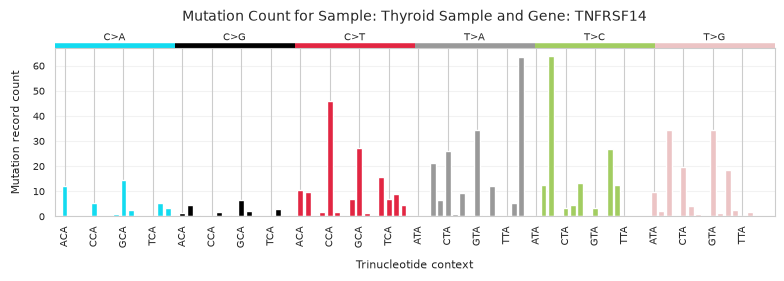

In [13]:
plot_sbs96_matrix(corr_matrix, sample_label="Thyroid Sample", gene="TNFRSF14", save_image=False)

In [46]:
def signatures_visualization(
        expected_counts_per_signature: pd.DataFrame, 
        normalized_matrix: pd.DataFrame,
        n_top_signatures: int = 10,
        data_normalize: bool = False,
        save_image: bool = False
    ) -> None:


    import matplotlib.pyplot as plt
    import seaborn as sns
    sns.set_style('whitegrid')
    sns.set_palette("coolwarm")
    plt.rcParams['figure.dpi'] = 300
    plt.rcParams['savefig.dpi'] = 300

    total_counts_per_signature = expected_counts_per_signature.sum(axis=0)
    top_sbs = total_counts_per_signature.nlargest(n_top_signatures).index

    if data_normalize:
            total_mutations = normalized_matrix["count"].sum()
            normalized_matrix["count"] /= total_mutations
            expected_counts_per_signature /= total_mutations

    expected_counts_top_sbs = expected_counts_per_signature.loc[:, top_sbs]


#     sub_colors = {
#     "C>A": "#13DBF0",
#     "C>G": "#000000",
#     "C>T": "#E22642",
#     "T>A": "#999999",
#     "T>C": "#A2CD61",
#     "T>G": "#ECC4C5",
# }

    fig, ax = plt.subplots(figsize=(8, 5))

    x = np.arange(len(normalized_matrix))
    bottom = np.zeros(len(normalized_matrix))

    for signature in expected_counts_top_sbs.columns:
        values = expected_counts_top_sbs[signature].to_numpy()
        ax.bar(x, 
               values, 
               bottom=bottom, 
               label=f"Signature {signature} ({values.sum():.2f})")
        bottom += values

    ax.plot(
        x,
        normalized_matrix["count"].to_numpy(),
        color='gray',
        alpha=0.5,
        label=f"Observed Mutations"
        
    )

    tick_positions = range(0, len(normalized_matrix), 4)
    ax.set_xticks(
        tick_positions,
        [normalized_matrix["mut_type"].iloc[i] for i in tick_positions]
    )

    # for i, tick_label in zip(tick_positions, ax.get_xticklabels()):
    #     tick_label.set_color(
    #         sub_colors[normalized_matrix["sub"].iloc[i]]
    # )

    ax.tick_params(axis="x", labelrotation=90, labelsize=7)
    ax.tick_params(axis="y", labelsize=7)
    ax.legend(title='Legend', bbox_to_anchor=(0.02, 1), 
              loc='upper left', title_fontsize=8, fontsize=7)
    ax.set_xlabel("Trinucleotide context", fontsize=8, labelpad=8)
    ax.set_ylabel("Mutation record", fontsize=8, labelpad=8)
    fig.tight_layout()

    ax.set_title('EM Derived Signature Contributions vs Observed Mutations',
                 fontsize=10, pad=20)
    if save_image:
        plt.savefig('images/signature_image.png', dpi=300, bbox_inches="tight")
    fig.show()

/tmp/ipykernel_1130/687346863.py:82: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


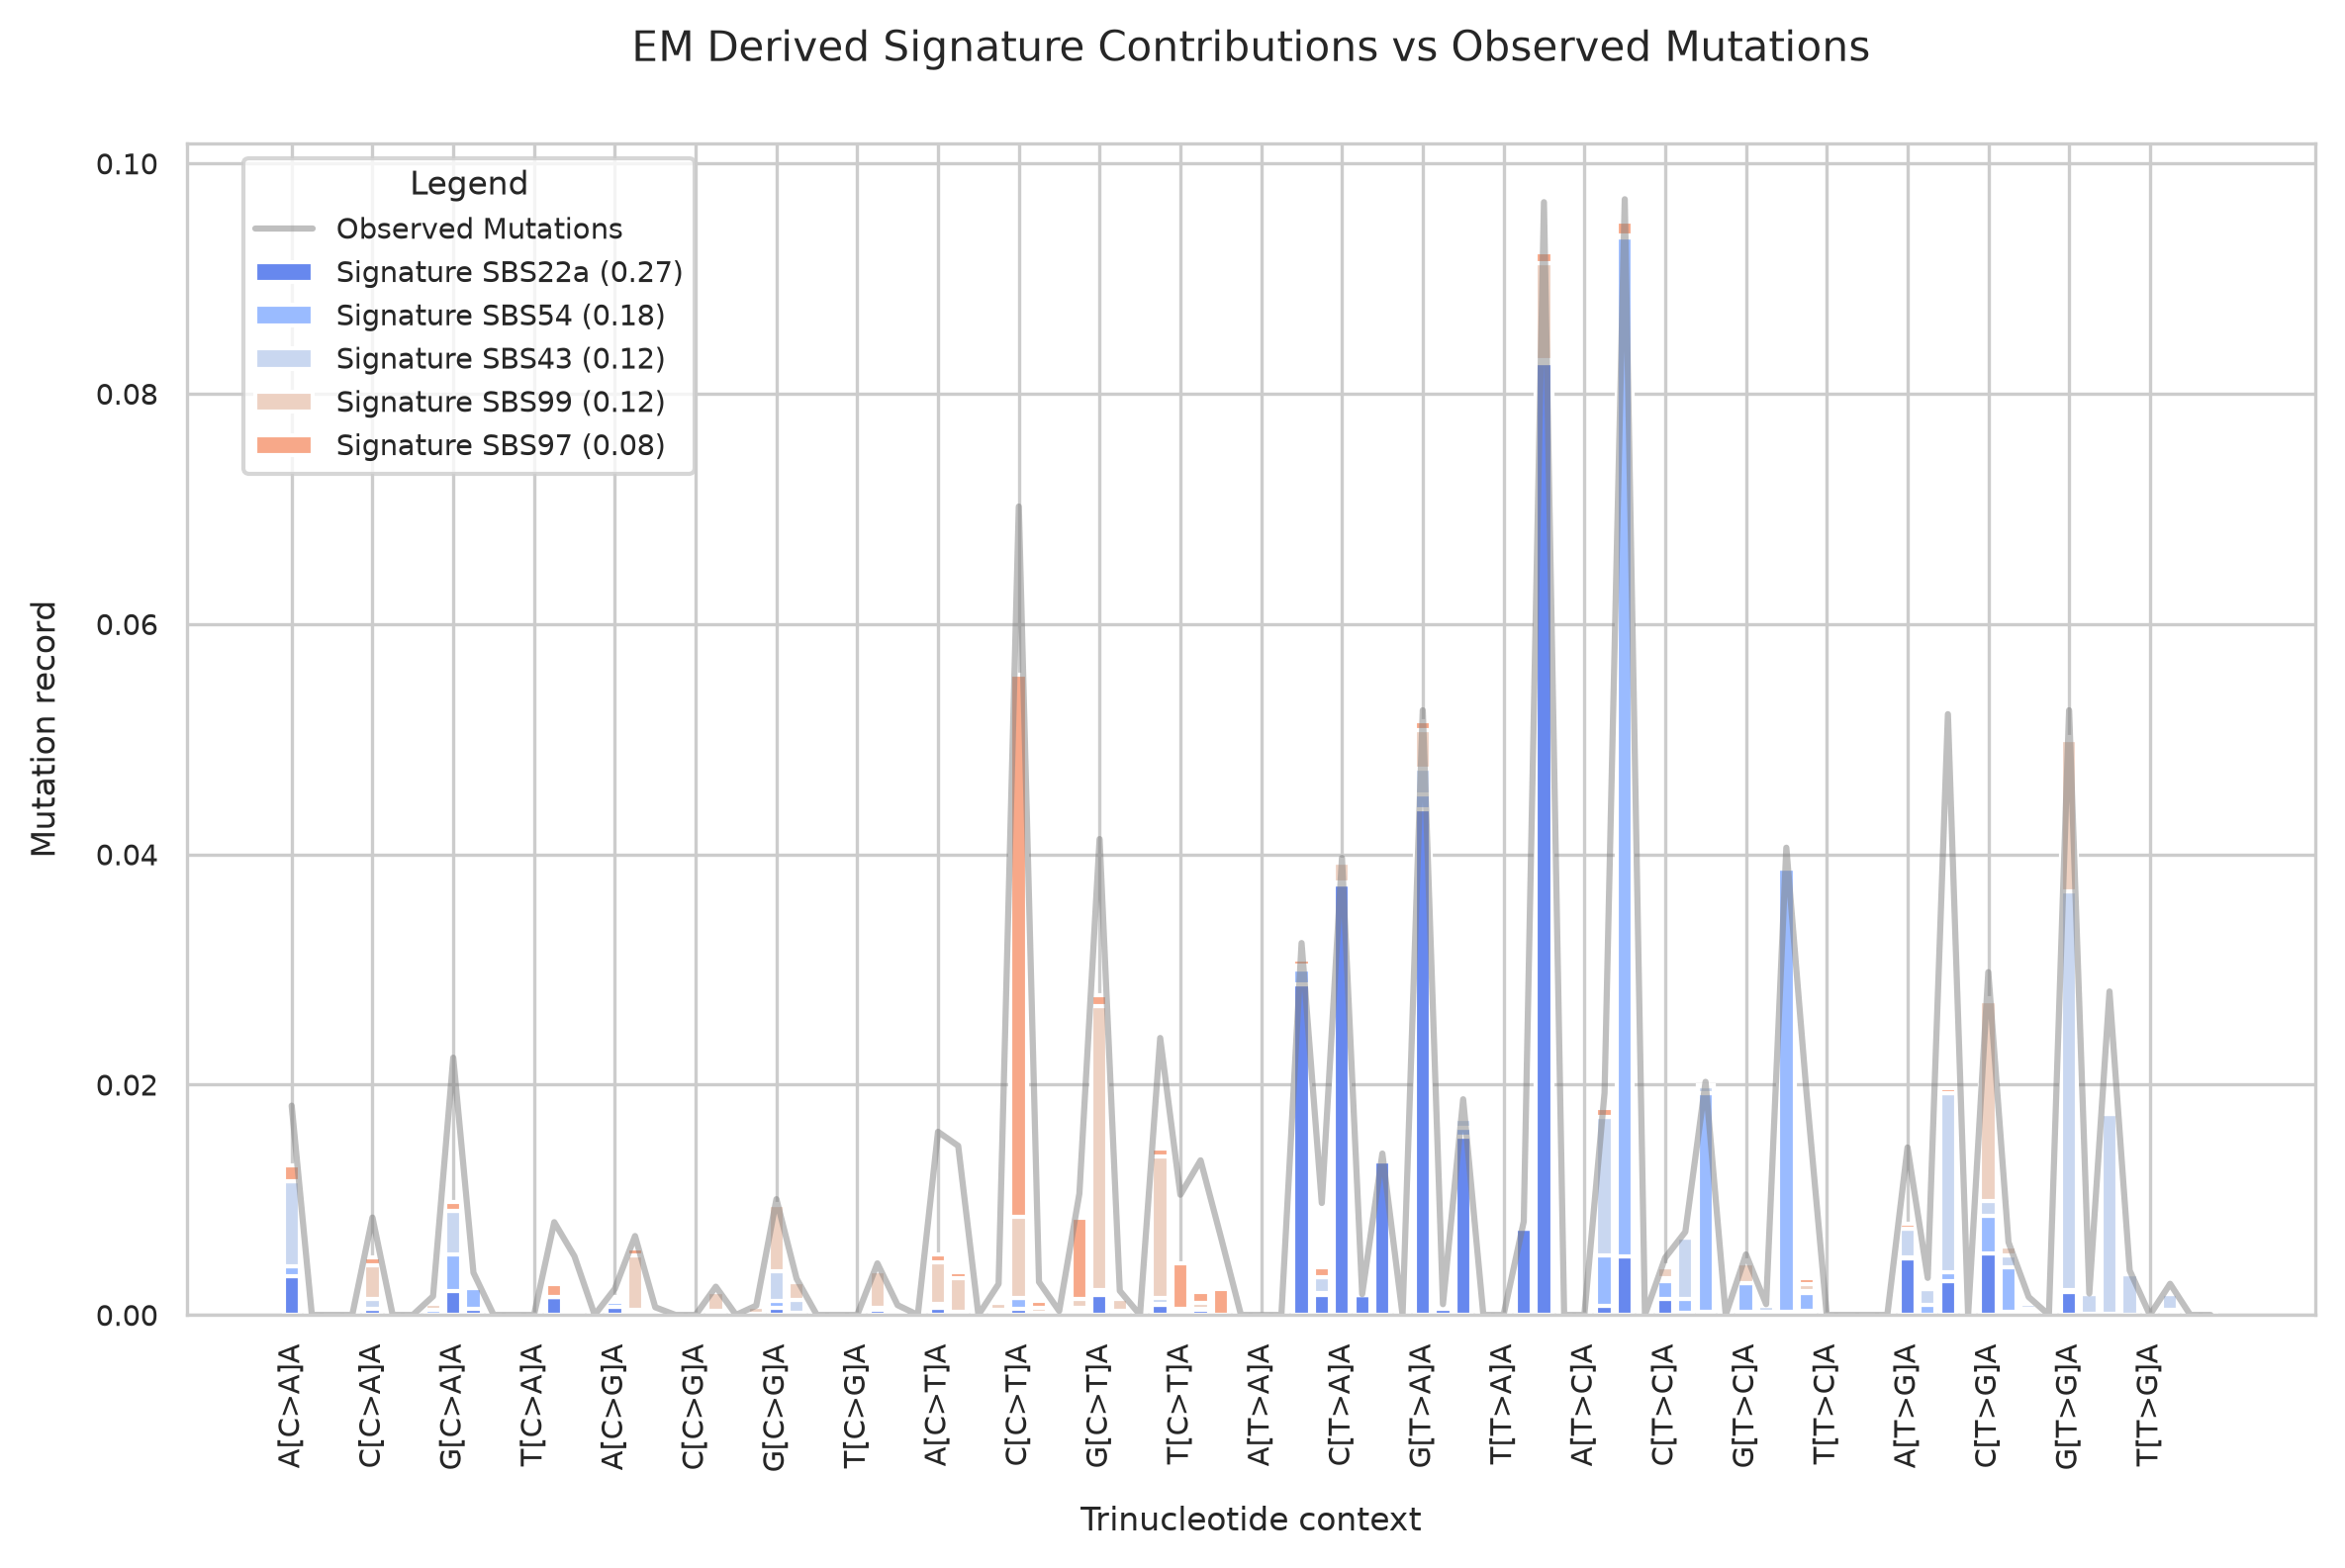

In [47]:
signatures_visualization(expected_counts_per_signature=expected_counts_per_signature, 
                         normalized_matrix=normalized_mutation_df,
                         data_normalize=True,
                         n_top_signatures=5, 
                         save_image=True)

In [64]:
len(normalized_mutation_df)

96